# 04 · Class weighting and decision tree

This notebook extends the original project baseline with a class-weighted logistic regression and a decision tree. It trains all three models on the same training rows and compares them on the same validation rows. The reserved test partition is not used to fit, score, select a model, or choose a threshold in this notebook.

**Questions for today:**
- How does class weighting change the logistic regression's fraud detection and false alerts?
- Can a simple decision tree improve the precision–recall trade-off on this dataset?

**Run:** use the project Python environment and choose **Run All**. The full PaySim data is processed; training may take several minutes.

**Important limitations:** PaySim is synthetic. The random transaction split is not a chronological or account-disjoint evaluation, and earlier exploratory analysis summarized the full dataset, including the now-reserved test partition. Model and threshold selection on the validation set can make validation results optimistic; final test-set scoring remains for later. Scores from the weighted model should not automatically be interpreted as calibrated fraud probabilities.

In [1]:
from pathlib import Path
import sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import sklearn, joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits
import sys as _sys
_sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
from paydev import (SEED, FEATURES, NUMERIC, CATEGORICAL, SPLIT, EXPECTED_SHA256,
                    find_root, data_path, load_dataset, stratified_splits)

ROOT = find_root()
DATA_PATH = data_path(ROOT)
print("Dataset:", DATA_PATH.relative_to(ROOT).as_posix())
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}")

Dataset: data/raw/PS_20174392719_1491204439457_log.csv
Python 3.15.2 | pandas 3.1.1 | NumPy 2.5.4 | scikit-learn 1.9.1


## 1. Reproduce the baseline data split

This uses the exact fingerprint, features, seed, stratification and two-stage 70/15/15 splitting procedure in notebook 03. The assumed prediction point is before transaction completion. Account IDs, post-transaction balances and the existing fraud flag are excluded; availability of both pre-transaction balances is an explicit assumption.

In [2]:
df, actual_sha256 = load_dataset(ROOT)
print("Dataset SHA-256:", actual_sha256)
y = df["isFraud"].to_numpy(copy=True)
train_ids, val_ids, test_ids = stratified_splits(y, seed=SEED)
splits = pd.DataFrame([{ "partition": name, "transactions": len(ids), "fraud": int(y[ids].sum()),
                         "fraud_rate_percent": 100 * float(y[ids].mean())}
                       for name, ids in [("Train", train_ids), ("Validation", val_ids), ("Test (reserved)", test_ids)]]).set_index("partition")
display(splits)

Dataset SHA-256: 16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b


,transactions,fraud,fraud_rate_percent
partition,,,
Train,4453834,5749,0.129080
Validation,954393,1232,0.129087
Test (reserved),954393,1232,0.129087


## 2. Define the models

All models use the same input features and independently fit the same numeric scaler and one-hot encoder **on training data only**. The decision tree does not require scaling, but uses it here to keep preprocessing consistent with the proposal.

- **Logistic regression:** the original unweighted baseline, retrained here for a same-run comparison.
- **Weighted logistic regression:** the same model with `class_weight="balanced"`, which increases the importance of the minority class during training.
- **Decision tree:** a single unweighted tree, with fixed `max_depth=8` and `min_samples_leaf=100` to limit overfitting. These are initial settings, not a tuned optimum.

No resampling or hyperparameter search is performed.

In [3]:
preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC),
    ("type", OneHotEncoder(handle_unknown="ignore", dtype=np.float32, sparse_output=False), CATEGORICAL),
], remainder="drop", sparse_threshold=0)
models = {
    "Logistic regression": Pipeline([("preprocess", clone(preprocess)), ("classifier", LogisticRegression(solver="lbfgs", max_iter=200, random_state=SEED))]),
    "Weighted logistic regression": Pipeline([("preprocess", clone(preprocess)), ("classifier", LogisticRegression(solver="lbfgs", max_iter=200, class_weight="balanced", random_state=SEED))]),
    "Decision tree": Pipeline([("preprocess", clone(preprocess)), ("classifier", DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=SEED))]),
}
print("Training features:", FEATURES)
print("Models:", ", ".join(models))

Training features: ['step', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'type']
Models: Logistic regression, Weighted logistic regression, Decision tree


## 3. Train on the training split

All three models are refitted within this run, avoiding comparisons between checkpoints created under different package versions. Convergence warnings stop the notebook rather than silently accepting an unfinished logistic fit.

In [4]:
X_train = df.iloc[train_ids][FEATURES]
X_val = df.iloc[val_ids][FEATURES]
y_train, y_val = y[train_ids], y[val_ids]
fit_times = {}
for name, model in models.items():
    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as captured, threadpool_limits(limits=4):
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train, y_train)
    problems = [str(w.message) for w in captured if issubclass(w.category, ConvergenceWarning)]
    if problems:
        raise RuntimeError(f"{name} did not converge: {'; '.join(problems)}")
    fit_times[name] = time.perf_counter() - start
    print(f"{name}: trained in {fit_times[name]:.1f} seconds")
print("Training complete. Test rows remain reserved.")

Logistic regression: trained in 5.6 seconds
Weighted logistic regression: trained in 7.7 seconds
Decision tree: trained in 33.2 seconds
Training complete. Test rows remain reserved.


## 4. Validation comparison

Average precision (AP) summarizes the precision–recall curve as a step-wise quantity; it is distinct from trapezoidal PR-AUC. Default-threshold results use 0.5 for every model. The F1-selected threshold for each model is chosen **on this same validation set**, so its F1 is an optimistic selection estimate and must not be treated as final test performance.

Class-weighted probabilities need not be calibrated. Alert volume and false positives matter alongside recall.

In [5]:
scores = {}
curves = {}
selected = {}
def measure(y_true, score, threshold):
    prediction = score >= threshold
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    return {"threshold": float(threshold), "precision": precision_score(y_true, prediction, zero_division=0),
            "recall": recall_score(y_true, prediction, zero_division=0), "F1": f1_score(y_true, prediction, zero_division=0),
            "false_positives": int(fp), "false_negatives": int(fn), "alerts": int(fp + tp),
            "alert_rate_percent": 100 * (fp + tp) / len(y_true)}
rows = []
for name, model in models.items():
    with threadpool_limits(limits=4):
        score = model.predict_proba(X_val)[:, 1]
    scores[name] = score
    p, r, t = precision_recall_curve(y_val, score)
    f1 = np.divide(2*p[:-1]*r[:-1], p[:-1]+r[:-1], out=np.zeros_like(t), where=(p[:-1]+r[:-1]) != 0)
    best = int(np.argmax(f1))
    selected[name] = float(t[best])
    curves[name] = (p, r)
    ap, roc = float(average_precision_score(y_val, score)), float(roc_auc_score(y_val, score))
    for label, threshold in [("Default 0.50", 0.5), ("F1 selected on validation", selected[name])]:
        rows.append({"model": name, "operating_point": label, "average_precision": ap, "ROC_AUC": roc,
                     **measure(y_val, score, threshold), "training_seconds": fit_times[name]})
results = pd.DataFrame(rows).set_index(["model", "operating_point"])
display(results.round(4))
print(f"Validation fraud prevalence: {y_val.mean():.4%}; validation rows: {len(y_val):,}")

average_precision  \
model                        operating_point                                
Logistic regression          Default 0.50                          0.1781   
                             F1 selected on validation             0.1781   
Weighted logistic regression Default 0.50                          0.1438   
                             F1 selected on validation             0.1438   
Decision tree                Default 0.50                          0.6281   
                             F1 selected on validation             0.6281   

                                                        ROC_AUC  threshold  \
model                        operating_point                                 
Logistic regression          Default 0.50                0.9317     0.5000   
                             F1 selected on validation   0.9317     0.0681   
Weighted logistic regression Default 0.50                0.9801     0.5000   
                             F1 selected on validation   0.9801     0.9999   
Decision tree                Default 0.50                0.9821     0.5000   
                             F1 selected on validation   0.9821     0.3784   

                                                        precision  recall  \
model                        operating_point                                
Logistic regression          Default 0.50                  0.9010  0.0739   
                             F1 selected on validation     0.2423  0.2354   
Weighted logistic regression Default 0.50                  0.0173  0.9302   
                             F1 selected on validation     0.2917  0.2159   
Decision tree                Default 0.50                  0.9057  0.4756   
                             F1 selected on validation     0.7719  0.5576   

                                                            F1  \
model                        operating_point                     
Logistic regression          Default 0.50               0.1365   
                             F1 selected on validation  0.2388   
Weighted logistic regression Default 0.50               0.0340   
                             F1 selected on validation  0.2481   
Decision tree                Default 0.50               0.6237   
                             F1 selected on validation  0.6475   

                                                        false_positives  \
model                        operating_point                              
Logistic regression          Default 0.50                            10   
                             F1 selected on validation              907   
Weighted logistic regression Default 0.50                         65050   
                             F1 selected on validation              646   
Decision tree                Default 0.50                            61   
                             F1 selected on validation              203   

                                                        false_negatives  \
model                        operating_point                              
Logistic regression          Default 0.50                          1141   
                             F1 selected on validation              942   
Weighted logistic regression Default 0.50                            86   
                             F1 selected on validation              966   
Decision tree                Default 0.50                           646   
                             F1 selected on validation              545   

                                                        alerts  \
model                        operating_point                     
Logistic regression          Default 0.50                  101   
                             F1 selected on validation    1197   
Weighted logistic regression Default 0.50                66196   
                             F1 selected on validation     912   
Decision tree                Default 0.50                  647   
    

Validation fraud prevalence: 0.1291%; validation rows: 954,393


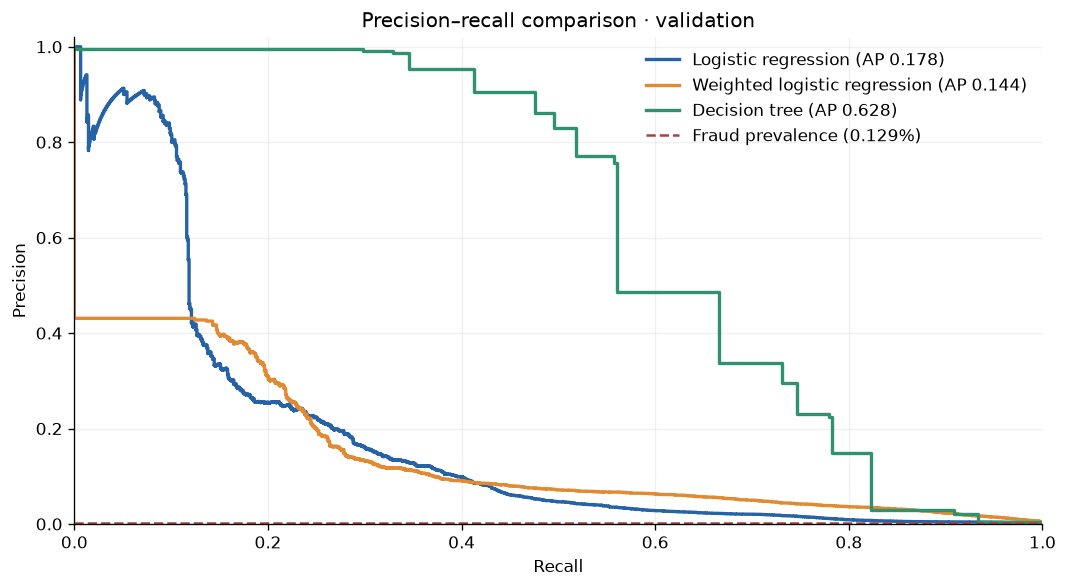

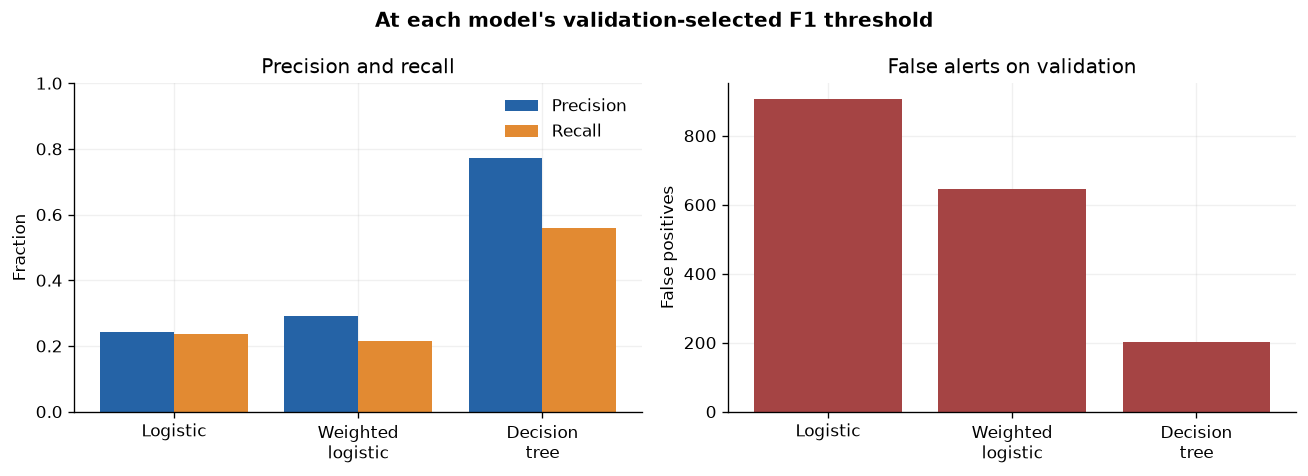

In [8]:
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .18, "axes.axisbelow": True})
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#2563a6", "#e28a32", "#2f916d"]
for (name, (p, r)), color in zip(curves.items(), colors):
    ax.step(r, p, where="post", lw=2, color=color, label=f"{name} (AP {average_precision_score(y_val, scores[name]):.3f})")
ax.axhline(y_val.mean(), color="#a54444", linestyle="--", label=f"Fraud prevalence ({y_val.mean():.3%})")
ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02), title="Precision–recall comparison · validation")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

selected_rows = results.xs("F1 selected on validation", level="operating_point")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(selected_rows))
axes[0].bar(x - .2, selected_rows["precision"], .4, label="Precision", color="#2563a6")
axes[0].bar(x + .2, selected_rows["recall"], .4, label="Recall", color="#e28a32")
axes[0].set(title="Precision and recall", ylabel="Fraction", ylim=(0, 1), xticks=x, xticklabels=["Logistic", "Weighted\nlogistic", "Decision\ntree"])
axes[0].legend(frameon=False)
axes[1].bar(x, selected_rows["false_positives"], color="#a54444")
axes[1].set(title="False alerts on validation", ylabel="False positives", xticks=x, xticklabels=["Logistic", "Weighted\nlogistic", "Decision\ntree"])
fig.suptitle("At each model's validation-selected F1 threshold", fontweight="bold")
fig.tight_layout()
plt.show()

## 5. Save today's checkpoints

The two new checkpoints contain the trained pipeline, selected validation threshold, split procedure, feature list, dataset fingerprint and software versions. They are small enough for Git. Never load joblib checkpoints from untrusted sources. Rerunning this cell replaces these two generated checkpoints.

In [7]:
checkpoint_paths = {"Weighted logistic regression": "weighted_logistic_regression.joblib", "Decision tree": "decision_tree_baseline.joblib"}
for name, filename in checkpoint_paths.items():
    checkpoint = {"pipeline": models[name], "model_name": name, "threshold": selected[name],
                  "threshold_selection": "max F1 on validation", "features": FEATURES, "seed": SEED,
                  "split": "stratified 70/15/15, two train_test_split calls", "dataset_sha256": actual_sha256,
                  "validation_average_precision": float(average_precision_score(y_val, scores[name])),
                  "validation_roc_auc": float(roc_auc_score(y_val, scores[name])),
                  "python_version": sys.version.split()[0], "numpy_version": np.__version__,
                  "pandas_version": pd.__version__, "sklearn_version": sklearn.__version__}
    path = ROOT / "models" / filename
    path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(checkpoint, path, compress=3)
    print(f"Saved {path.relative_to(ROOT).as_posix()} ({path.stat().st_size:,} bytes)")
print("No test rows were scored.")

Saved models/weighted_logistic_regression.joblib (1,936 bytes)
Saved models/decision_tree_baseline.joblib (4,770 bytes)
No test rows were scored.


## Next steps

Compare Random Forest, KNN, Naive Bayes, XGBoost and the ANN from the project proposal. Continue using the same split and clearly document computational limits. Add feature and imbalance ablations, then decide on a model using training/validation data before final test scoring. A time-based or account-aware evaluation should be reported separately.